<a href="https://colab.research.google.com/github/Raiqueeee/ML/blob/main/Random_Forest_Classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# 1. Required library imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print('Libraries imported successfully')

Libraries imported successfully


In [23]:
# 2. Load the Iris dataset (built into scikit-learn)
iris = load_iris()
X = iris.data
y = iris.target
feature_names = iris.feature_names
target_names = iris.target_names

# Create a DataFrame for easy exploration
df = pd.DataFrame(X, columns=feature_names)
df['species'] = pd.Categorical.from_codes(y, target_names)

print('Dataset loaded successfully')
print('Features:', feature_names)
print('Target classes:', list(target_names))

Dataset loaded successfully
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


In [24]:
# 3. Basic data exploration
print('Dataset shape (rows, features):', X.shape)
print('Feature names:', feature_names)
print('Target names:', list(target_names))
print()
print('First 5 rows:')
print(df.head())
print()
print('Descriptive statistics:')
print(df.describe())
print()
print('Class distribution:')
print(df['species'].value_counts())
print()
print('Missing values per column:')
print(df.isnull().sum())

Dataset shape (rows, features): (150, 4)
Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Target names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

First 5 rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  

Descriptive statistics:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   


In [25]:
# 4. Preprocessing note and train/test split
# Note: tree-based models like Random Forest do NOT require feature scaling,
# because splits are based on feature thresholds, not distances.
# The Iris dataset is clean (no missing values), so no imputation is needed.
# We therefore go straight to a stratified 80/20 train/test split.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print('Training set shape:', X_train.shape)
print('Test set shape:', X_test.shape)
print('Training class counts:', np.bincount(y_train))
print('Test class counts:', np.bincount(y_test))

Training set shape: (120, 4)
Test set shape: (30, 4)
Training class counts: [40 40 40]
Test class counts: [10 10 10]


In [26]:
# 5. Initialize and train the Random Forest Classifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

print('Model trained successfully')
print(model)

Model trained successfully
RandomForestClassifier(random_state=42)


In [27]:
# 6. Make predictions and evaluate the model
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print(f'Accuracy: {accuracy:.4f} ({accuracy*100:.2f}%)')
print()
print('Classification Report:')
print(classification_report(y_test, y_pred, target_names=target_names))
print('Confusion Matrix:')
print(cm)

Accuracy: 0.9000 (90.00%)

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.82      0.90      0.86        10
   virginica       0.89      0.80      0.84        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

Confusion Matrix:
[[10  0  0]
 [ 0  9  1]
 [ 0  2  8]]


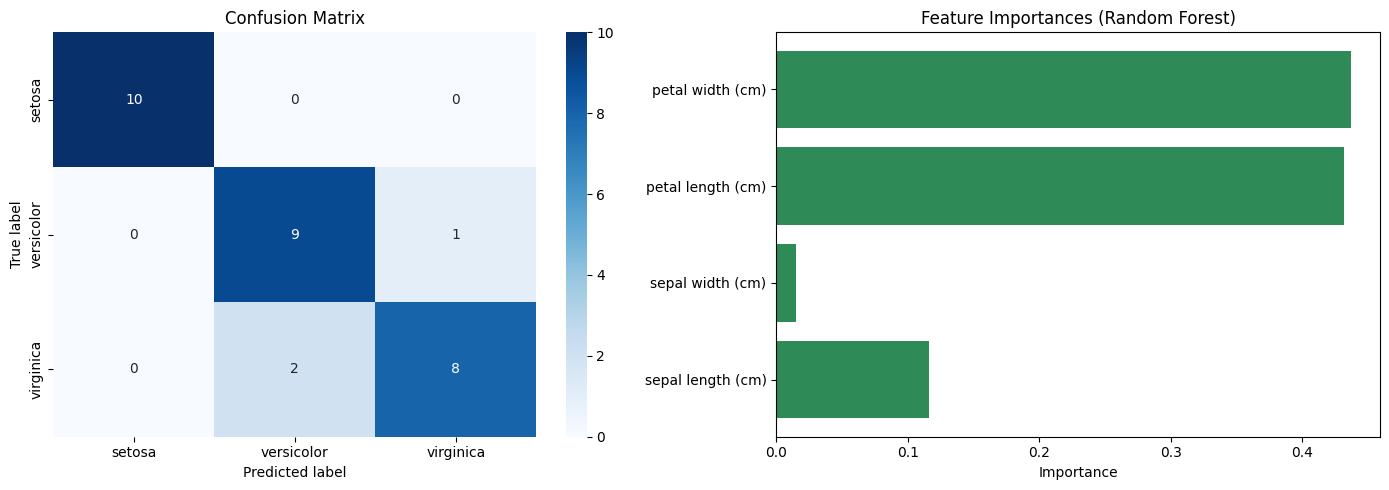

Feature importances:
sepal length (cm): 0.1163
sepal width (cm): 0.0150
petal length (cm): 0.4315
petal width (cm): 0.4372


In [28]:
# 7. Visualize results: confusion matrix heatmap and feature importances
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=target_names, yticklabels=target_names)
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted label')
axes[0].set_ylabel('True label')
importances = model.feature_importances_
axes[1].barh(feature_names, importances, color='seagreen')
axes[1].set_title('Feature Importances (Random Forest)')
axes[1].set_xlabel('Importance')
plt.tight_layout()
plt.show()
print('Feature importances:')
for name, imp in zip(feature_names, importances):
    print(f'{name}: {imp:.4f}')